In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import os
import seaborn as sns

import sys
sys.path.append('../')

import pipeline_utility as pu

In [2]:
from analysis import small_label_settings, large_label_settings
plt.style.use('default')
plt.rcParams.update(small_label_settings)

In [3]:
df = pd.read_csv(os.path.join('../experiments/full_pipeline/final_data.csv'))

In [4]:
# Add original order index within each replicate
df['orig_order'] = df.groupby('replicate').cumcount()

# Now sort by sample, reads, and orig_order
df_s = df.sort_values(
    by=['sample', 'reads', 'orig_order'],
    ascending=[True, False, True]
)

In [5]:
def barcodes_to_colors(df):
    sort = df.sort_values(
        by=['sample', 'reads'],
        ascending=[True, False]
    )

    n_barcodes = sort['barcode'].nunique()
    ordered_barcodes = sort['barcode'].unique()
    
    colors = np.array(["#ff4d6f", "#579ea4", "#df7713", "#f9c000", "#86ad34",
              "#5d7298", "#81b28d", "#7e1a2f", "#2d2651", "#c8350d", "#bd777a",
              '#1a5f7a', '#8b4c8f', '#4a9eff', '#ffd93d', '#3dcc8e', '#ff8c42',
              '#e63946', '#a0c334', '#6b4e71', '#00b4d8'])
    unedited_barcode = 'NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE'
    
    repeats = -(-n_barcodes // len(colors))
    colors_extended = np.tile(colors, repeats)[:n_barcodes]

    color_dict = dict()

    i = 0
    for barcode in sort['barcode'].unique():
        if barcode == unedited_barcode:
            color_dict[barcode] = '#aaaaaa'
        else:
            color_dict[barcode] = colors_extended[i]
            i = i + 1

    return ordered_barcodes, color_dict

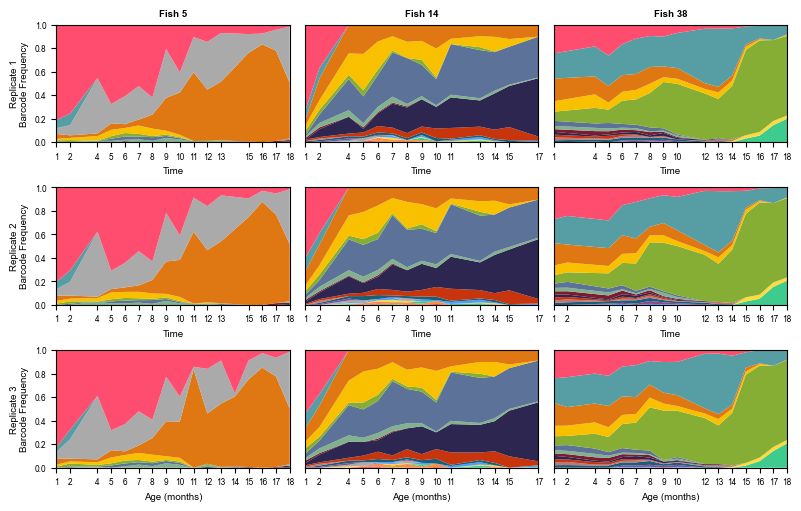

In [6]:
fig, ax = plt.subplots(3, 3, figsize = (7.9, 5), constrained_layout=True)
for i, fish in enumerate(['fish5', 'fish14', 'fish38']):
    fish_df = df.query('fish == @fish')
    order, color_dict = pu.barcodes_to_colors(fish_df)
    
    for rep in range(3):
        pu.plot_muller(df_s, fish, ax = ax[rep, i], replicate = rep + 1, order = order, color_dict = color_dict)
        if i > 0:
            ax[rep, i].set_ylabel('')
            ax[rep, i].set_yticks([])
        if i == 0:
            ax[rep, i].set_ylabel(f'Replicate {rep+1}\nBarcode Frequency')
        if rep == 0:
            ax[rep, i].set_title(f'Fish {fish[4:]}', fontweight='bold')
        if rep == 2:
            ax[rep, i].set_xlabel('Age (months)')

In [7]:
subset = df

counts = (
    subset
    .groupby(['fish', 'sample', 'replicate'])['barcode']
    .nunique()
    .reset_index(name='n_barcodes')
)
counts.head()

,fish,sample,replicate,n_barcodes
0,fish1,1,1,6
1,fish1,1,2,8
2,fish1,1,3,6
3,fish1,2,1,8
4,fish1,2,2,8


In [8]:
pivot = counts.pivot_table(
    index=['fish', 'sample'],
    columns='replicate',
    values='n_barcodes',
    fill_value=0
).reset_index()
pivot.head()

replicate,fish,sample,1,2,3
0,fish1,1,6.0,8.0,6.0
1,fish1,2,8.0,8.0,9.0
2,fish1,5,8.0,8.0,8.0
3,fish1,6,8.0,8.0,8.0
4,fish1,7,7.0,6.0,6.0


In [9]:
pairs = [
    (1, 2, "1 vs 2"),
    (2, 3, "2 vs 3"),
    (1, 3, "1 vs 3"),
]

rows = []
for a, b, label in pairs:
    rows.append(
        pivot.assign(
            x=pivot[a],
            y=pivot[b],
            comparison=label
        )[["fish", "sample", "x", "y", "comparison"]]
    )

plot_df = pd.concat(rows, ignore_index=True)
plot_df.head()

replicate,fish,sample,x,y,comparison
0,fish1,1,6.0,8.0,1 vs 2
1,fish1,2,8.0,8.0,1 vs 2
2,fish1,5,8.0,8.0,1 vs 2
3,fish1,6,8.0,8.0,1 vs 2
4,fish1,7,7.0,6.0,1 vs 2


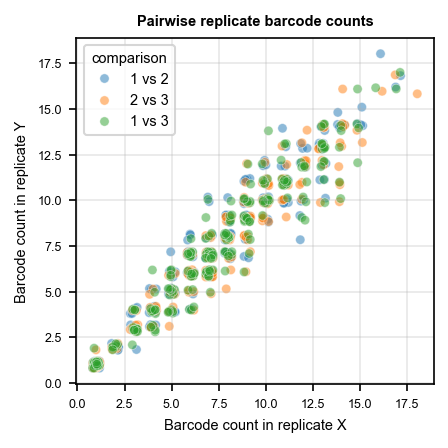

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df_nonzero = plot_df[(plot_df['x'] > 0) & (plot_df['y'] > 0)]

def add_jitter(x, amount=0.2):
    return x + np.random.uniform(-amount, amount, size=len(x))

plot_df_jitter = plot_df_nonzero.copy()
plot_df_jitter['x_j'] = add_jitter(plot_df_jitter['x'])
plot_df_jitter['y_j'] = add_jitter(plot_df_jitter['y'])

plt.figure(figsize=(3,3), dpi = 150)
sns.scatterplot(
    data=plot_df_jitter,
    x='x_j',
    y='y_j',
    hue='comparison',
    s=20,
    alpha=0.5
)

plt.xlabel("Barcode count in replicate X")
plt.ylabel("Barcode count in replicate Y")
plt.title("Pairwise replicate barcode counts", fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:
from sklearn.metrics import r2_score
overall_r2 = r2_score(plot_df_nonzero['y'], plot_df_nonzero['x'])
print("Overall R²:", overall_r2)


Overall R²: 0.9359847271173769
